# PS3: RNN (SimpleRNN) for character-level text generation
Corpus: Shakespeare text, downloaded automatically.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers

EPOCHS = 15
SEQ_LEN = 40

In [2]:
path = keras.utils.get_file(
    "shakespeare.txt", "https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt")
text = open(path, encoding="utf-8").read().lower()[:200000]
chars = sorted(set(text))
char_to_id = {c: i for i, c in enumerate(chars)}
print("Characters:", len(text), " Vocabulary:", len(chars))
print(text[:300])

Characters: 200000  Vocabulary: 37
first citizen:
before we proceed any further, hear me speak.

all:
speak, speak.

first citizen:
you are all resolved rather to die than to famish?

all:
resolved. resolved.

first citizen:
first, you know caius marcius is chief enemy to the people.

all:
we know't, we know't.

first citizen:
let us


In [3]:
encoded = np.array([char_to_id[c] for c in text])
starts = range(0, len(encoded) - SEQ_LEN, 3)
X = np.array([encoded[i:i + SEQ_LEN] for i in starts])
y = np.array([encoded[i + SEQ_LEN] for i in starts])
print("X:", X.shape, " y:", y.shape)

X: (66654, 40)  y: (66654,)


In [4]:
model = keras.Sequential([
    layers.Input((None,)),
    layers.Embedding(len(chars), 64),
    layers.SimpleRNN(256),
    layers.Dense(len(chars), activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, None, 64)       │         2,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 256)            │        82,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 37)             │         9,509 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 94,053 (367.39 KB)

 Trainable params: 94,053 (367.39 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(X, y, epochs=EPOCHS, batch_size=128, validation_split=0.1, verbose=2)

Epoch 1/15


469/469 - 13s - 28ms/step - accuracy: 0.2802 - loss: 2.5583 - val_accuracy: 0.3266 - val_loss: 2.3278


Epoch 2/15


469/469 - 13s - 28ms/step - accuracy: 0.3642 - loss: 2.1814 - val_accuracy: 0.3704 - val_loss: 2.1835


Epoch 3/15


469/469 - 12s - 27ms/step - accuracy: 0.4052 - loss: 2.0252 - val_accuracy: 0.3858 - val_loss: 2.0966


... (20 outputs left out)

Epoch 14/15


469/469 - 11s - 24ms/step - accuracy: 0.5713 - loss: 1.3913 - val_accuracy: 0.4611 - val_loss: 1.8993


Epoch 15/15


469/469 - 11s - 24ms/step - accuracy: 0.5785 - loss: 1.3590 - val_accuracy: 0.4647 - val_loss: 1.9001


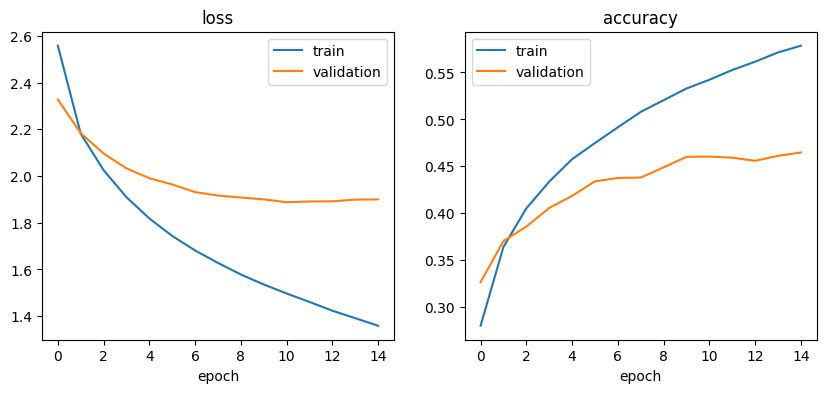

Final validation accuracy: 0.4647
Validation perplexity: 6.69


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i, metric in enumerate(["loss", "accuracy"]):
    ax[i].plot(history.history[metric], label="train")
    ax[i].plot(history.history["val_" + metric], label="validation")
    ax[i].set_title(metric)
    ax[i].set_xlabel("epoch")
    ax[i].legend()
plt.show()
print(f"Final validation accuracy: {history.history['val_accuracy'][-1]:.4f}")
print(f"Validation perplexity: {np.exp(history.history['val_loss'][-1]):.2f}")

In [7]:
def generate(seed, length=300, temperature=0.5):
    out = seed.lower()
    for _ in range(length):
        x = np.array([[char_to_id[c] for c in out[-SEQ_LEN:]]])
        probs = model(x, training=False).numpy()[0].astype("float64")
        probs = np.exp(np.log(probs + 1e-9) / temperature)
        probs /= probs.sum()
        out += chars[np.random.choice(len(chars), p=probs)]
    return out


seed = text[1000:1000 + SEQ_LEN]
for t in [0.2, 0.5, 1.0]:
    print(f"--- temperature {t} ---")
    print(generate(seed, temperature=t))
    print()

--- temperature 0.2 ---


second citizen:
would you proceed especians and that is the people to his perither.

cominius:
you have so him heart the deed to the common are the people to his country are the deed to the cornour the people the commen are the people to his compon my state, and the commen are the people to his aster to be speak against the deed to the va

--- temperature 0.5 ---


second citizen:
would you proceed especion of him and to rumpen my name?

coriolanus:
aul speak hore, the commen are the people here,
the general end to the vanous will be ampected me.

cominius:
which i cannot to him hath dower sor, till hand well be speak,
the good man to the cannot but his prive to ace, gown but to as it the marcer: th

--- temperature 1.0 ---


second citizen:
would you proceed especions, they maneer mielf, and hose actot-
porty weels,
goves, a wool,
get you shall be in maneby'', ay you.

second een:
theretage!

marcius:
i th'ilsent of
our wish this
rot, friends thou are hames:
the bornot, bodre in muthous pack to kill:
are well:
then'd, i would,
upon ot for u'drear aptochade
ag

